# 03. Tendencias temporales 2022–2025

Serie de 4 ediciones del DENUE y el artefacto censal de 2024. Ventanas reales: 12m, 12m y 6m.

In [1]:
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

DB = Path("data/denue.db")
if not DB.exists():
    DB = Path("../data/denue.db")

EDICIONES = ["2022_11", "2023_11", "2024_11", "2025_05"]
ETIQUETAS = ["nov-2022", "nov-2023", "nov-2024", "may-2025"]
TRANSICIONES = [("2022_11", "2023_11"), ("2023_11", "2024_11"), ("2024_11", "2025_05")]

con = sqlite3.connect(DB)
datos = {ed: pd.read_sql(f"SELECT * FROM denue_{ed}", con) for ed in EDICIONES}
trans = {}
for e1, e2 in TRANSICIONES:
    s = pd.read_sql(f"SELECT * FROM t_{e1}__{e2}_sobrevivientes", con)
    n = pd.read_sql(f"SELECT * FROM t_{e1}__{e2}_nacimientos", con)
    m = pd.read_sql(f"SELECT * FROM t_{e1}__{e2}_muertes", con)
    trans[(e1, e2)] = (s, n, m)
cohortes = pd.read_sql("SELECT * FROM cohortes", con)
con.close()

print("Ediciones cargadas:", {ed: len(datos[ed]) for ed in EDICIONES})


Ediciones cargadas: {'2022_11': 41638, '2023_11': 41783, '2024_11': 46923, '2025_05': 47408}


## 1. Total de unidades económicas (2022–2025)

nov-2022: 41,638
nov-2023: 41,783
nov-2024: 46,923
may-2025: 47,408


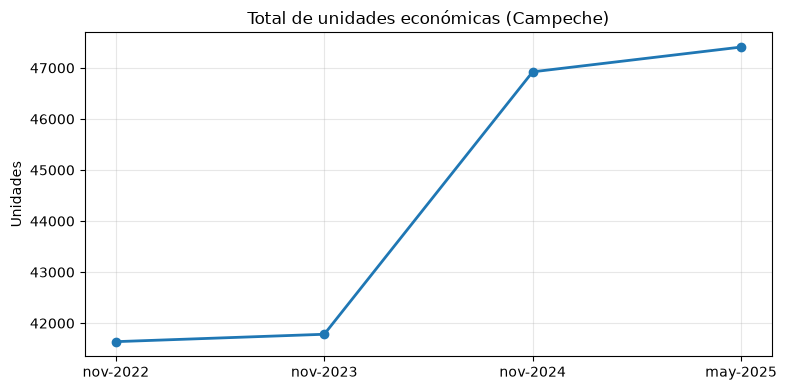

In [2]:
totales = [len(datos[ed]) for ed in EDICIONES]
for ed, t in zip(ETIQUETAS, totales):
    print(f'{ed}: {t:,}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ETIQUETAS, totales, marker='o', linewidth=2, color='#1f77b4')
ax.set_title('Total de unidades económicas (Campeche)')
ax.set_ylabel('Unidades')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Tasas por transición

In [3]:
filas = []
for e1, e2 in TRANSICIONES:
    s, n, m = trans[(e1, e2)]
    base = len(datos[e1])
    filas.append({
        'transicion': f'{e1}->{e2}',
        'U_base': base,
        'S': len(s), 'N': len(n), 'M': len(m),
        'supervivencia': len(s) / base * 100,
        'entrada': len(n) / base * 100,
        'salida': len(m) / base * 100,
    })
res = pd.DataFrame(filas)
res[['transicion', 'U_base', 'S', 'N', 'M', 'supervivencia', 'entrada', 'salida']].round(1)

,transicion,U_base,S,N,M,supervivencia,entrada,salida
0,2022_11->2023_11,41638,41242,541,396,99.0,1.3,1.0
1,2023_11->2024_11,41783,28984,17939,12799,69.4,42.9,30.6
2,2024_11->2025_05,46923,45752,1656,1171,97.5,3.5,2.5


## 3. El artefacto censal de 2024

La edición **11/2024** proviene de los Censos Económicos (actualización *exhaustiva*), no de una actualización regular. Esto produce una rotación anormalmente alta en la transición 2023→2024.

La **tasa de supervivencia** por transición lo revela con claridad:

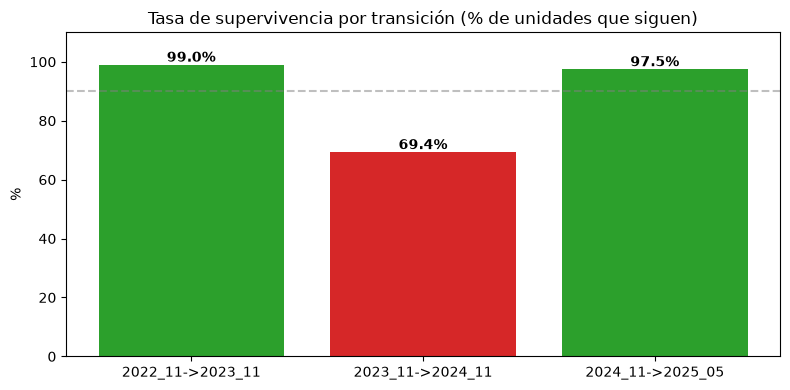

In [4]:
colores = ['#2ca02c', '#d62728', '#2ca02c']
fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(res['transicion'], res['supervivencia'], color=colores)
for b, v in zip(barras, res['supervivencia']):
    ax.text(b.get_x() + b.get_width()/2, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
ax.axhline(90, color='gray', linestyle='--', alpha=0.5)
ax.set_ylim(0, 110)
ax.set_title('Tasa de supervivencia por transición (% de unidades que siguen)')
ax.set_ylabel('%')
plt.tight_layout()
plt.show()

**Interpretación:** la supervivencia cae de 99.0% (2022→2023) a **69.4%** (2023→2024) y se recupera a 97.5% (2024→2025). Una caída así de abrupta no refleja un colapso real de negocios, sino la **re-codificación masiva de CLEEs** que introduce el censo económico. El 42.9% de 'nacimientos' y 30.6% de 'muertes' en 2023→2024 son, en su mayoría, artefacto de cobertura, no creación/cierre real.

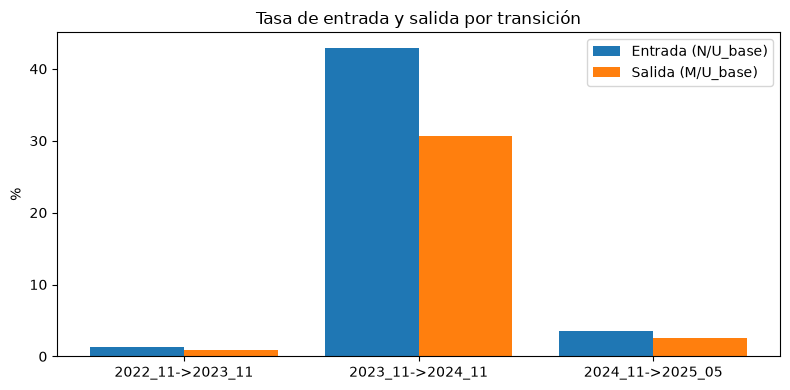

In [5]:
colores = ['#1f77b4', '#ff7f0e']
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(res))
ax.bar([i-0.2 for i in x], res['entrada'], width=0.4, label='Entrada (N/U_base)', color='#1f77b4')
ax.bar([i+0.2 for i in x], res['salida'], width=0.4, label='Salida (M/U_base)', color='#ff7f0e')
ax.set_xticks(list(x))
ax.set_xticklabels(res['transicion'])
ax.set_ylabel('%')
ax.set_title('Tasa de entrada y salida por transición')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Tendencia por municipio (selección)

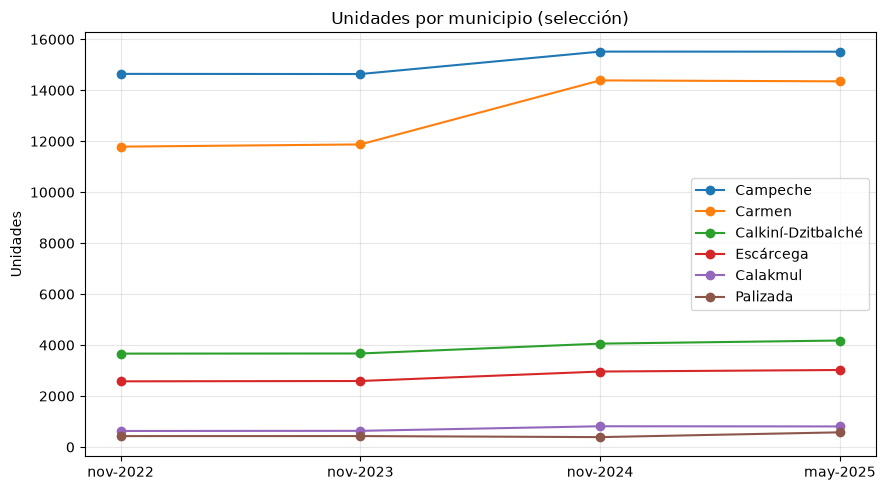

In [6]:
sel = ['Campeche', 'Carmen', 'Calkiní-Dzitbalché', 'Escárcega', 'Calakmul', 'Palizada']
fig, ax = plt.subplots(figsize=(9, 5))
for nombre in sel:
    serie = [int((datos[ed]['municipio'] == nombre).sum()) for ed in EDICIONES]
    ax.plot(ETIQUETAS, serie, marker='o', label=nombre)
ax.set_title('Unidades por municipio (selección)')
ax.set_ylabel('Unidades')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Por sector de servicios y grupo Tren Maya

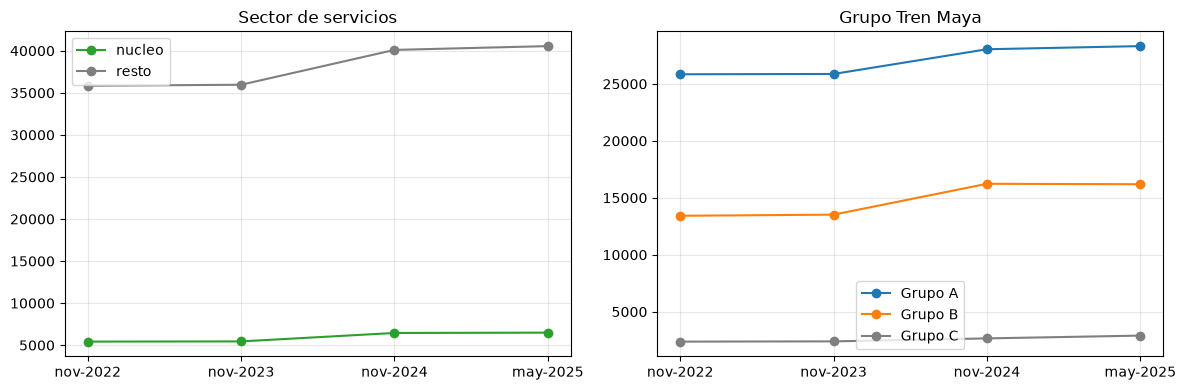

In [7]:
def serie_por(clave, valor):
    return [int((datos[ed][clave] == valor).sum()) for ed in EDICIONES]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for nivel, color in [('nucleo', '#2ca02c'), ('resto', '#7f7f7f')]:
    axes[0].plot(ETIQUETAS, serie_por('sector_servicios', nivel), marker='o', label=nivel, color=color)
axes[0].set_title('Sector de servicios')
axes[0].legend()
for grupo, color in [('A', '#1f77b4'), ('B', '#ff7f0e'), ('C', '#7f7f7f')]:
    axes[1].plot(ETIQUETAS, serie_por('grupo_tren', grupo), marker='o', label=f'Grupo {grupo}', color=color)
axes[1].set_title('Grupo Tren Maya')
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()